# 5 · Numerics guide: accuracy, speed, warnings

**Covered topics:** how the numerical settings (order, grid size `N`, binning `n_bin`, integration rule, tolerances) trade accuracy against run time, how to read PyToF's warnings, and how to debug a calculation that does not converge.

All numbers in this notebook are measured live on the Wisdom & Hubbard (2016) Jupiter polytrope of notebook 1, for which the exact solution is known (`accuracy/references.py`). Run times depend on your machine and the ratios are what matters. More complete studies are in `accuracy/`.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from PyToF import ToF
from PyToF.messages import ConvergenceWarning, PyToFWarning, RenamedWarning
from tutorial_utils import Bessel, JUPITER_RADIUS


def run(N=1024, order=4, repeat=3, **options):
    """Relax the W&H Jupiter polytrope. Returns (model, best run time in s, iterations)."""
    X = ToF(N=N, order=order, R_ref=JUPITER_RADIUS, **options)
    X.set_barotrope(lambda P, param: np.sqrt(P))
    best = np.inf
    for _ in range(repeat):
        X.reset()
        tic = time.perf_counter()
        iterations = X.relax_to_barotrope()
        best = min(best, time.perf_counter() - tic)
    return X, best, iterations


def rel_error(X, n):
    """Relative error of J_2n against the exact solution."""
    return abs(X.Js[n] / Bessel[n] - 1)

plt.rcParams["figure.figsize"] = (5.2, 3.9)  # smaller default figures

## Order and grid size: accuracy versus time

Each point is one (order, $N$) combination, with

$$N = 2^5, 2^6, \ldots, 2^{12}.$$

The $x$ axis is the time of one complete `relax_to_barotrope()`, the $y$ axis the error of $J_2$, $J_4$ or $J_6$:

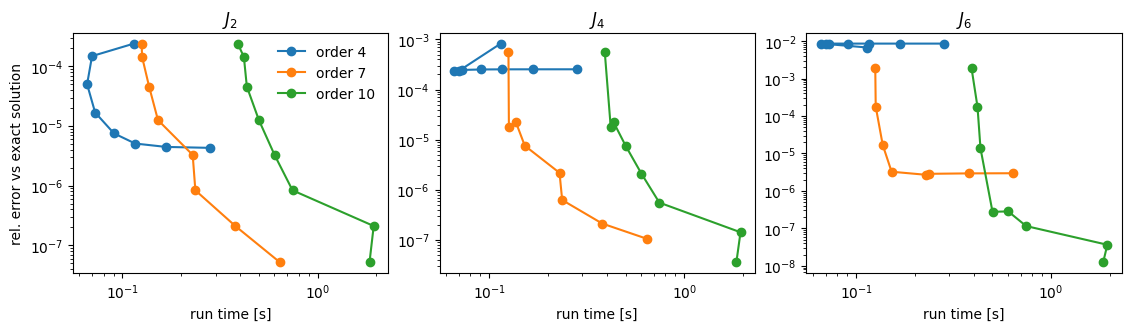

In [2]:
orders = [4, 7, 10]
Ns = [2**k for k in range(5, 13)]
results = {}
for order in orders:
    for N in Ns:
        X, t, it = run(N, order, repeat=1 if N > 1024 else 3)
        results[order, N] = (t, [rel_error(X, n) for n in (1, 2, 3)])

fig, axs = plt.subplots(1, 3, figsize=(11.2, 3.2), layout="constrained", sharex=True)
for order in orders:
    t = [results[order, N][0] for N in Ns]
    for k, ax in enumerate(axs):
        ax.plot(t, [results[order, N][1][k] for N in Ns], "o-", label=f"order {order}")
for k, ax in enumerate(axs, start=1):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("run time [s]")
    ax.set_title(f"$J_{{{2 * k}}}$")
axs[0].set_ylabel("rel. error vs exact solution")
axs[0].legend(frameon=False);

Read it as a cost–accuracy curve: from the left (small $N$) to the right (large $N$) the error falls until it flattens at the floor of the order. For a given target error, take the leftmost curve that gets there. For the three moments shown:

In [3]:
print("cheapest (order, N) reaching a given error for J2 / J4 / J6   [time]")
for target in (1e-3, 1e-4, 1e-5, 1e-6):
    line = []
    for k in range(3):
        best = min(((results[o, N][0], o, N) for o in orders for N in Ns if results[o, N][1][k] < target), default=None)
        line.append(f"{'--':>18s}" if best is None else f"order {best[1]:2d}, N={best[2]:5d} [{best[0]:.2f}s]")
    print(f"error < {target:.0e}: " + " | ".join(line))

cheapest (order, N) reaching a given error for J2 / J4 / J6   [time]
error < 1e-03: order  4, N=  128 [0.07s] | order  4, N=  128 [0.07s] | order  7, N=   64 [0.13s]
error < 1e-04: order  4, N=  128 [0.07s] | order  7, N=   64 [0.13s] | order  7, N=  128 [0.14s]
error < 1e-05: order  4, N=  512 [0.09s] | order  7, N=  256 [0.15s] | order  7, N=  256 [0.15s]
error < 1e-06: order  7, N= 1024 [0.24s] | order  7, N= 1024 [0.24s] | order 10, N=  256 [0.50s]


Run times grow with the order and, above a few hundred points, with $N$. Below that, a calculation is dominated by a fixed cost per iteration, so going from 64 to 512 points costs little time, especially at low order.

## Binning: `n_bin`

The slowest step of the Theory of Figures, the update of the figure functions, can be computed on a coarser grid of `n_bin` points and interpolated back (`n_bin=-1`, the default, uses all `N` points). This helps most at high order and large $N$, where that step dominates the run time. Time and error for $N=4096$, 10th order:

In [4]:
N = 4096
print(f"{'N/n_bin':>8s}{'time [s]':>10s}{'err J2':>10s}{'err J4':>10s}{'err J6':>10s}")
for factor in (1, 4, 16, 64, 256):
    X, t, it = run(N, 10, n_bin=N // factor, repeat=2)
    print(f"{factor:8d}{t:10.2f}{rel_error(X, 1):10.1e}{rel_error(X, 2):10.1e}{rel_error(X, 3):10.1e}")

 N/n_bin  time [s]    err J2    err J4    err J6


       1      1.86   5.3e-08   3.6e-08   1.2e-08


       4      1.65   5.3e-08   3.6e-08   1.2e-08


      16      1.16   4.5e-08   2.3e-08   3.6e-09


      64      1.02   1.3e-06   1.8e-07   7.4e-06


     256      0.97   5.2e-05   8.9e-04   3.4e-03


Binning by a factor of up to 16 costs nothing in accuracy (the errors are even unchanged to the digits shown) and saves significant time. Beyond a factor of about 64 the interpolation error takes over. The time stops falling at about half of the unbinned value because the rest of the calculation (pressures, densities, integrals) still runs on all `N` points. `get_Js_errors()` takes the binning into account.

## Simpson's rule or the trapezoid rule

Pressure and the Theory of Figures integrals are evaluated with Simpson's rule by default (`use_simpson=True`), the trapezoid rule otherwise. For smooth profiles Simpson's rule is far more accurate at the same $N$ for a few percent more time:

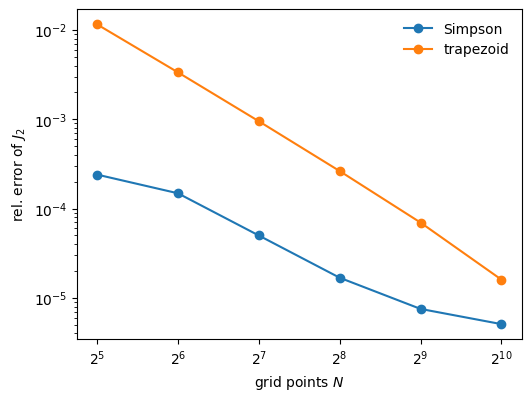

In [5]:
Ns_small = [2**k for k in range(5, 11)]
fig, ax = plt.subplots(layout="constrained")
for simpson in (True, False):
    errors = [rel_error(run(N, 4, use_simpson=simpson, repeat=1)[0], 1) for N in Ns_small]
    ax.plot(Ns_small, errors, "o-", label="Simpson" if simpson else "trapezoid")
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xlabel("grid points $N$")
ax.set_ylabel("rel. error of $J_2$")
ax.legend(frameon=False);

Simpson's rule is only safe where the density is smooth. PyToF checks for two symptoms and then switches to the trapezoid rule for the rest of the calculation, with an `AccuracyWarning` (`X.simpson_in_use` tells which rule is in use, `X.reset()` starts again with Simpson's rule): a non-equidistant grid, and a non-monotonic enclosed-mass function, which density jumps cause.

A third situation does not trigger a switch: a density with an infinite slope at the surface. A polytrope of index $n$ has the equation of state

$$P = K\rho^{1+1/n}.$$

Hydrostatic equilibrium near the surface then gives

$$\rho \propto (R-r)^n, \qquad \frac{\mathrm{d}\rho}{\mathrm{d}r} \propto (R-r)^{n-1},$$

whose slope is infinite at $r=R$ for $n<1$. Simpson's rule then makes the iteration converge slowly (the iteration count grows with $N$) or not at all, while the trapezoid rule is not affected.

PyToF warns with an `AccuracyWarning` in this case. In the third iteration of `relax_to_barotrope()` or `relax_to_density()` it estimates the exponent $n$ of this power law from the three outermost grid points and warns if the estimate is below the option `surface_exponent_warn` (default 0.9, and 0 switches the check off). The check is a heuristic: a large surface pressure `P0` ($\gtrsim 10^6$ Pa) hides the singularity from the three outermost points, so a `ConvergenceWarning` can still be the first sign. In both cases, use `use_simpson=False`:

In [6]:
def polytrope(n):
    X = ToF(N=1024, order=4, R_ref=JUPITER_RADIUS, baro_param=[n])
    X.set_barotrope(lambda P, param: P ** (param[0] / (param[0] + 1)))
    return X

with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    for n in (1.0, 0.8):
        for simpson in (True, False):
            X = polytrope(n)
            X.opts["use_simpson"] = simpson
            print(f"n = {n}, use_simpson = {simpson!s:5}: {X.relax_to_barotrope():3d} iterations")

n = 1.0, use_simpson = True :  17 iterations
n = 1.0, use_simpson = False:  17 iterations


PyToF/FunctionsToF.py:239: AccuracyWarning: The density near the surface behaves like (R - r)^0.86, below the limit 0.90 of the option surface_exponent_warn: its slope is (nearly) infinite there. Simpson's rule may then converge slowly or not at all (ConvergenceWarning); try use_simpson=False.
  warn_surface_slope(exponent, threshold)


n = 0.8, use_simpson = True : 100 iterations
n = 0.8, use_simpson = False:  19 iterations


## Tolerances

The iteration stops when the relative change of the moments, the densities and the rotational parameter falls below `dJ_tol`, `drho_tol` and `drot_tol` (default $10^{-10}$ each). There is nothing to gain from a tolerance far below the numerical error of the setting (previous sections: usually $10^{-6}$ to $10^{-9}$ for good settings), but a tolerance far above costs accuracy. For a calculation where you only need a few digits — scans, sampling — loosening it saves time:

In [7]:
reference, _, _ = run(1024, 7, dJ_tol=1e-12, drot_tol=1e-12, drho_tol=1e-12, repeat=1)
print(f"{'tolerance':>10s}{'iterations':>12s}{'time [s]':>10s}{'max|dJ/J|':>12s}")
for tol in (1e-4, 1e-6, 1e-8, 1e-10):
    X, t, it = run(1024, 7, dJ_tol=tol, drot_tol=tol, drho_tol=tol)
    print(f"{tol:10.0e}{it:12d}{t:10.3f}{np.max(np.abs(X.Js[1:] / reference.Js[1:] - 1)):12.1e}")

 tolerance  iterations  time [s]   max|dJ/J|


     1e-04           8     0.108     1.4e-05


     1e-06          11     0.145     1.9e-07


     1e-08          14     0.215     2.8e-09


     1e-10          18     0.260     9.1e-12


The achieved error is about the tolerance. The number of iterations falls from 18 to 8 for $10^{-10} \to 10^{-4}$. The iteration *limits* (`max_iter_relax_barotrope`, `max_iter_relax_density`, `max_iter_relax_shape`, `max_iter_density_update`) must be at least 2. Hitting one issues a `ConvergenceWarning`.

## Warnings

PyToF reports problems with Python's `warnings` module, so you decide what happens with them. They all derive from `PyToFWarning`:

| class | meaning |
|---|---|
| `ConvergenceWarning` | an iteration hit its limit before reaching the tolerance. The result is the last iterate |
| `AccuracyWarning` | the result is less accurate than requested, e.g. PyToF fell back from Simpson's rule to the trapezoid rule, or the density has an infinite slope at the surface (`surface_exponent_warn`) |
| `RenamedWarning` | you used an old name (an option, an attribute) that still works but will be removed |
| `PyToFWarning` | everything else: inconsistent radius, no error estimate available, ... |

Progress messages (summaries, timings, per-iteration traces) are not warnings. They are printed only for `verbosity >= 1`, see notebook 1. Three of the warning classes in action:

In [8]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")

    X = ToF(N=256, max_iter_relax_barotrope=3)  # a limit that is too small
    X.set_barotrope(lambda P, param: np.sqrt(P))
    X.relax_to_barotrope()

    ToF(MaxIterBar=50)  # old option name, from PyToF <= 1.7

    X = ToF(N=256, alphas=np.r_[1e5, np.zeros(11)])
    X.get_Js_errors()  # no error estimates for differential rotation

for w in caught:
    print(f"{w.category.__name__:18s}{str(w.message)}")

ConvergenceWarningdrot = 1e-03 > 1e-10, dJ = 5e-01 > 1e-10, drho = 1e-03 > 1e-10 after max_iter_relax_barotrope = 3 iterations.
RenamedWarning    The option 'MaxIterBar' was renamed to 'max_iter_relax_barotrope'. The old name still works but will be removed in a future version.
PyToFWarning      Accuracy when using differential rotation is unknown. PyToF provides no error estimates.


To silence one kind, ignore its class. To be strict, turn it into an error (useful in scripts where a non-converged model must not go unnoticed):

```python
warnings.filterwarnings("ignore", category=RenamedWarning)
warnings.filterwarnings("error", category=ConvergenceWarning)
```

## Debugging: `debug_plot`

If a calculation does not converge or gives odd results, the option `debug_plot` draws diagnostic figures. With `debug_plot="show"` they are displayed, for example in a notebook. With `debug_plot="save"` (or `True`) they are written as PNG files into the **current working directory**, called `debug_relax_<name>_<i>.png` and `debug_AlgoToF_<i>.png` with the first unused `i`. matplotlib is only imported in this case. It is slow and produces many figures, so use a small `N` and a low iteration limit. There are two kinds of figures, each a single figure that shows one iteration at a glance:

* `relax_to_barotrope()` / `relax_to_density()`, once per iteration: the density (with the previous iteration) and the density change since the previous iteration, the pressure from both integration rules and their relative deviation, and the convergence history with a few numbers. It is also drawn if the pressure comes out negative or not monotonic.
* The Theory of Figures algorithm (the same call as `relax_to_shape()`), once per step of its iteration: the density slope, the volume integrals $S_{2j}$ with Simpson's rule (light, solid) and the trapezoid rule (dark, dotted), the stability check of Simpson's rule (the enclosed mass $S_0$ must not increase with the radius), the shape functions that go into the step, and the new figure functions. The option `debug_primed=True` shows the primed volume integrals $S^\prime_{2j}$ instead.

Quantities that are expected to agree, such as the two integration rules or the current and the previous iteration, share a color, in a dark and a light shade, with the dark one dotted and drawn on top. In the figure of the Theory of Figures algorithm, black marks what does not belong to an index $j$, blue the check on $S_0$ (which is $j=0$), and otherwise the color gives the index $j$ of the quantity (see the legend in the figure).

To see where Simpson's rule fails, switch off its automatic fallback with `simpson_check=False`. The two-layer polytrope below has a density jump at a pressure of 30% of the central pressure. The run ends with the `PressureError` that PyToF would otherwise have avoided, after drawing the figures:

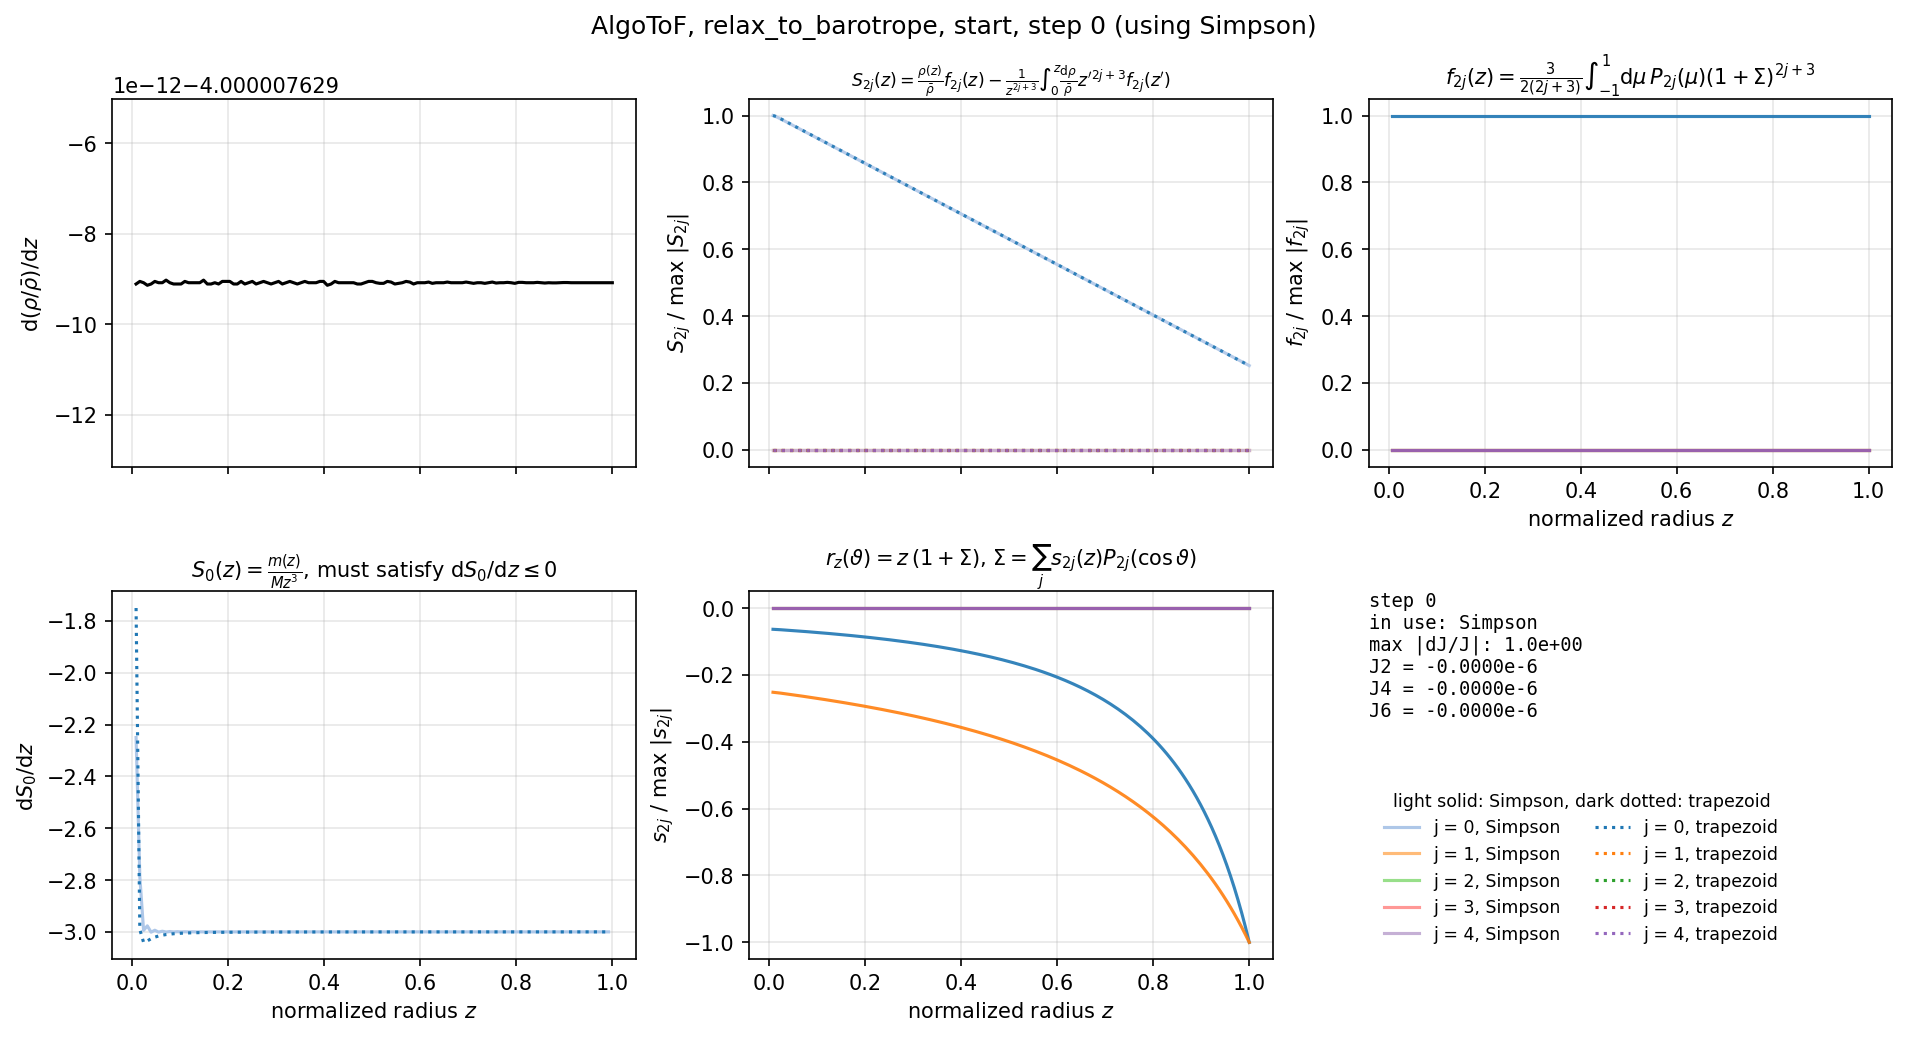

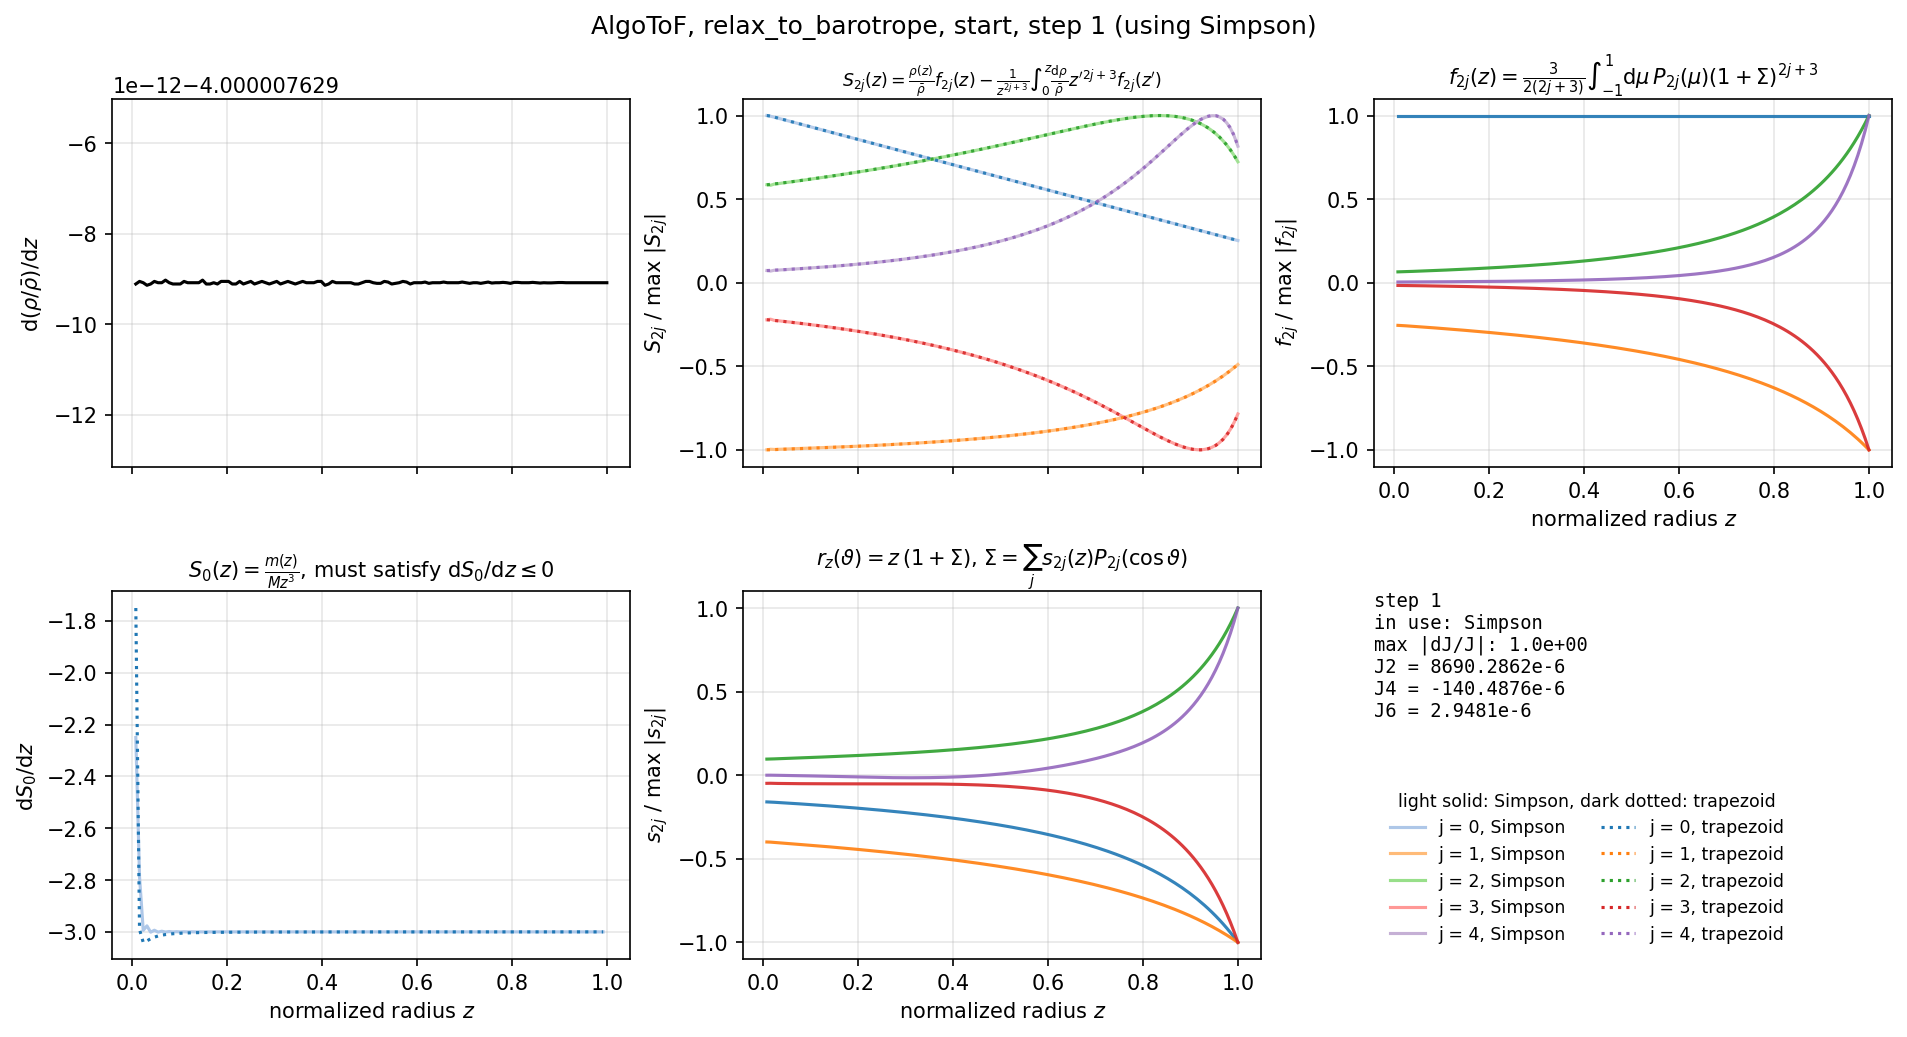

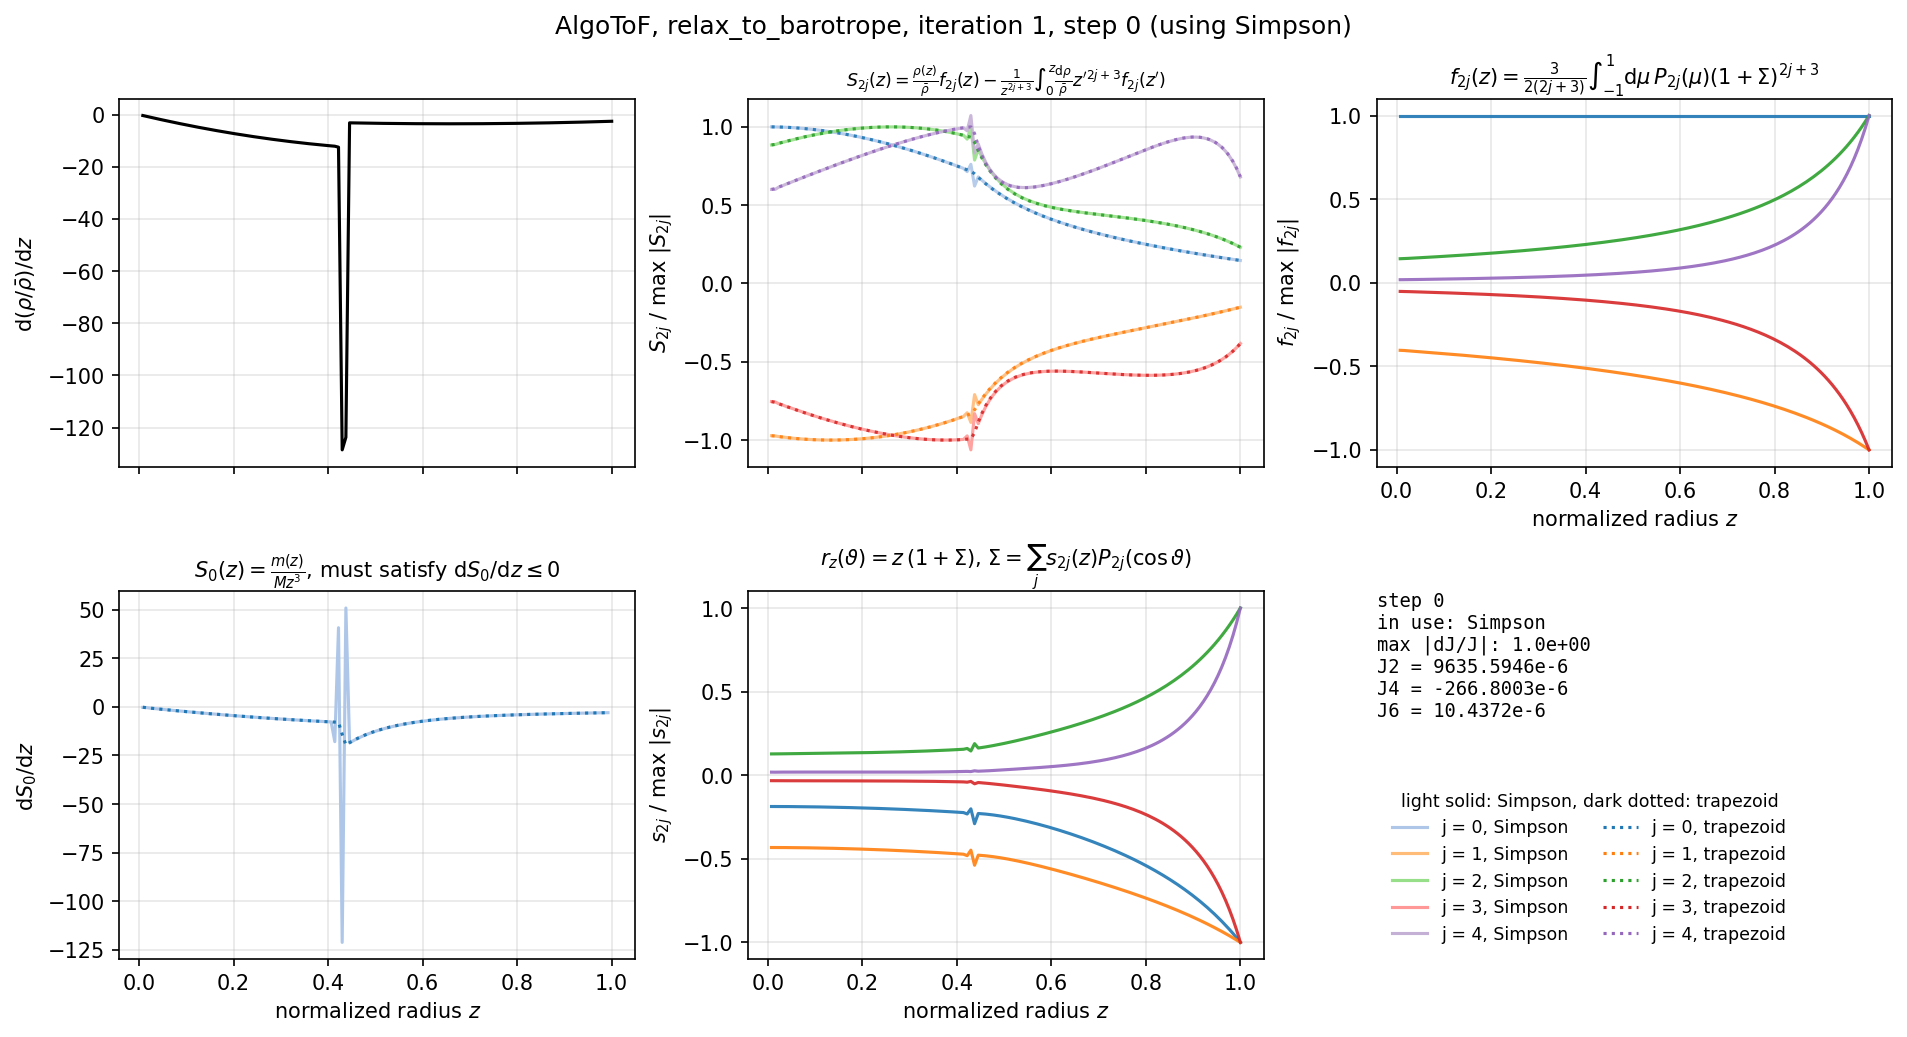

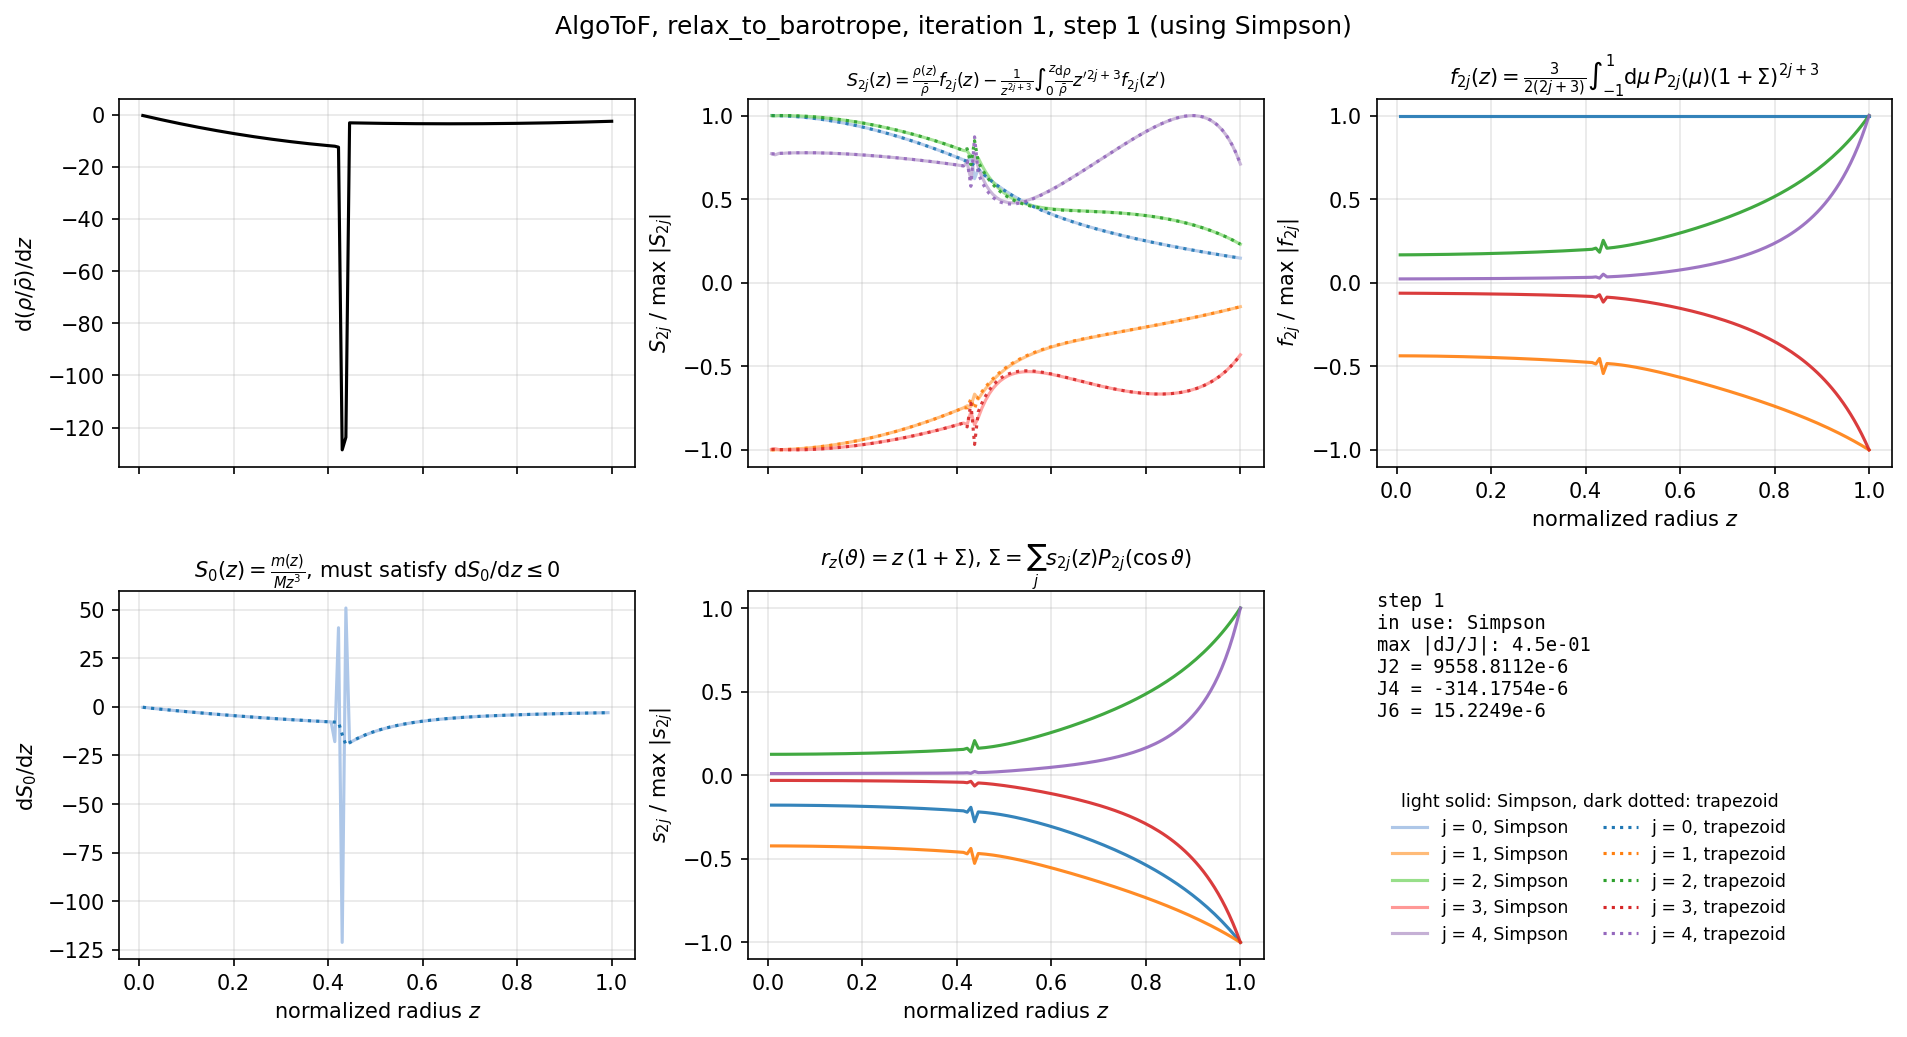

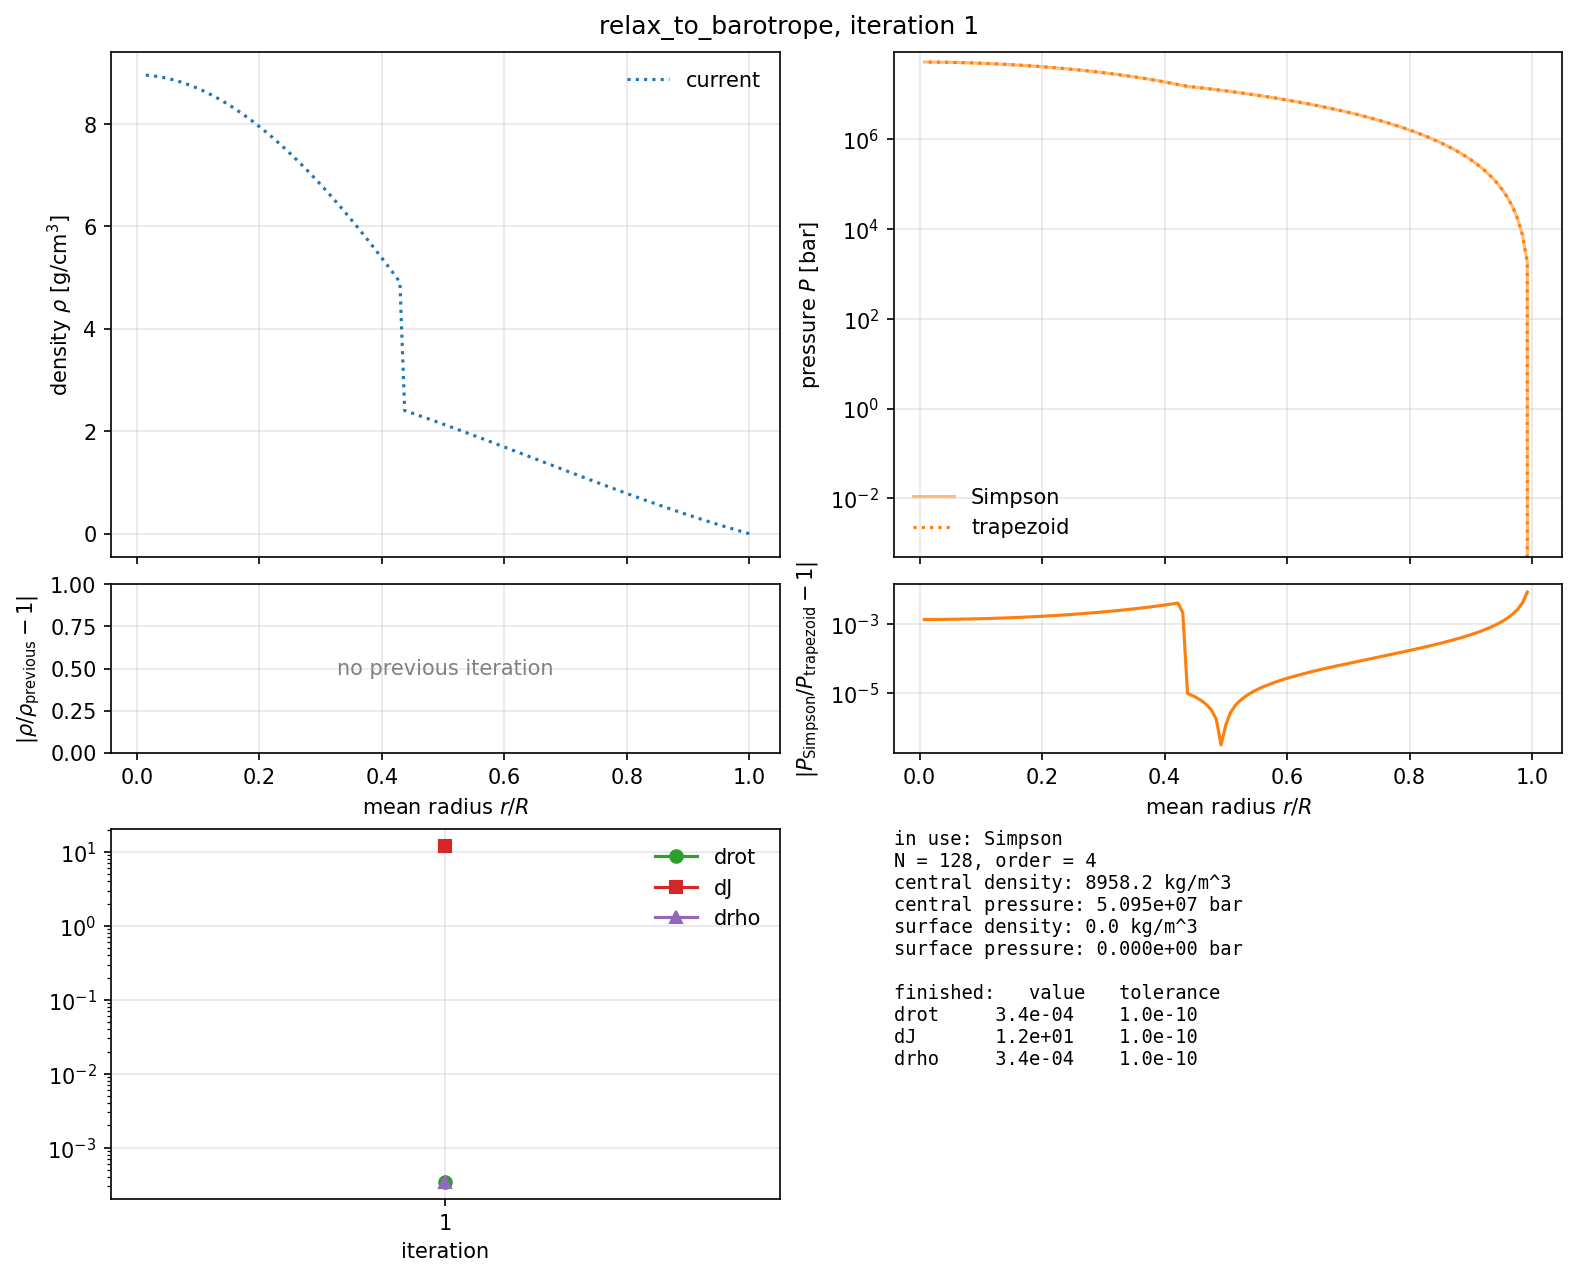

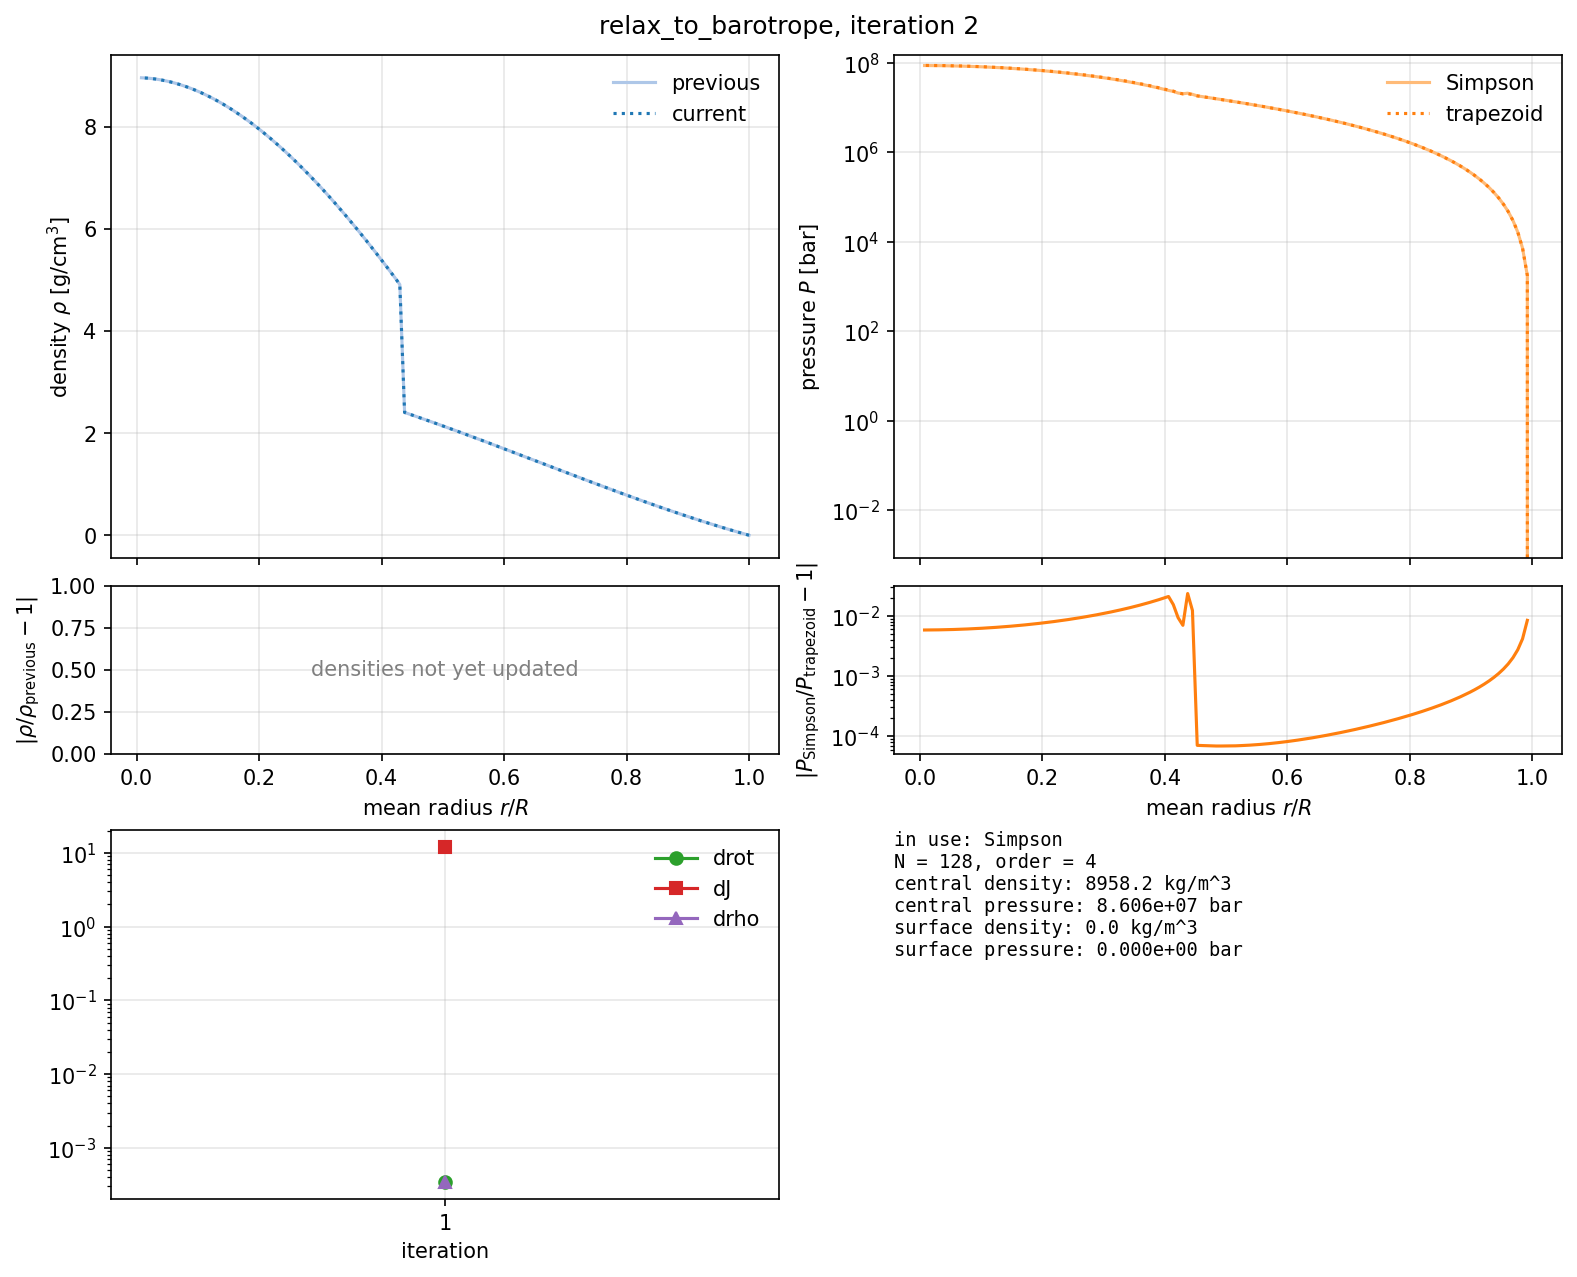

PressureError: Calculated pressure is not monotonically increasing! If you switched off the option simpson_check, Simpson's rule may have failed.


In [9]:
def two_layer(P, param):
    return np.sqrt(P) * (1 + 1.0 * (P > 0.3 * np.max(P)))

from PyToF.messages import PressureError

X = ToF(N=128, order=4, R_ref=JUPITER_RADIUS, debug_plot="show", simpson_check=False,
    max_iter_relax_barotrope=3)
X.set_barotrope(two_layer)
try:
    X.relax_to_barotrope()
except PressureError as error:
    print("PressureError:", error)

Every `relax_to_barotrope()` starts with a shape calculation for the initial density, a linear ramp without a jump, so the first figures of the run show a smooth density. The barotrope, and with it the jump, only enters in the first density update after that. The figures that follow show the jump: its spike in the density slope enters the volume integrals, and in the figures of the Theory of Figures algorithm the Simpson volume integrals (solid) deviate from the trapezoid ones (dotted) at the jump ($z \approx 0.43$). The panel "check" is the stability test of Simpson's rule: the enclosed mass $S_0$ must not increase with the radius, and with Simpson's rule it does at the jump (red crosses), while the trapezoid rule stays monotonic. With the check switched on, PyToF falls back to the trapezoid rule at exactly this point. Without it the error carries on into the pressure, and the last figure marks where the pressure becomes non-monotonic (red cross in the pressure panel, again at the jump) before the `PressureError` stops the run.

Saving the figures of a short run instead of displaying them, which is not run here because the tutorials do not write any files:

```python
X = ToF(N=64, order=4, R_ref=JUPITER_RADIUS, debug_plot="save", max_iter_relax_barotrope=3)
X.set_barotrope(lambda P, param: np.sqrt(P))
X.relax_to_barotrope()
# writes debug_relax_barotrope_0.png, ... and debug_AlgoToF_0.png, ...
```

## Takeaways: recommended settings

| goal | order | $N$ | other |
|---|---|---|---|
| quick look, $J_2$ to $10^{-4}$ | 4 | 128 | defaults |
| $J_2$ to $10^{-5}$, $J_4$ to $10^{-4}$ | 4–7 | 256–512 | defaults |
| $J_2$, $J_4$ to $10^{-6}$ | 7 | 1024 | defaults |
| $J_6$ to $10^{-6}$ or better, $J_8$ and higher | 10 | 256 and up | `n_bin=N//16` for $N \gtrsim 4096$ |

1. Choose the order by the highest moment you need, then the grid by the accuracy you need. Check by repeating with the next larger `N`.
2. Use `get_Js_errors()` (solid body rotation) as a guide, but verify unusual profiles yourself.
3. Treat a `ConvergenceWarning` as a real problem: look at the numbers in the message, then try `use_simpson=False` (for a density with an infinite slope at the surface, PyToF warns about it early), a larger `max_iter_*`, or a smaller `N`.